[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_event/BA_L7_event.ipynb)

# BA_L7_event: Event study of Ether around 13 Ethereum upgrades

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Market-model event study of Ether (ETH) around the formal schedule and implementation dates of 13 Ethereum upgrade families (Istanbul 2019 to Fusaka 2025): cumulative abnormal returns from day -10 to +10 against an equal-weighted index of 11 other coins, estimation window [-250, -31] days, with cross-sectional, BMP and sign tests (EODHD daily closes to October 2026).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Method

The normal return of Ether (ETH) is predicted by a market model estimated on days $[-250, -31]$ before the event:

$$ R_t = \alpha + \beta R_{m,t} + u_t, \qquad \mathrm{AR}_t = R_t - \hat\alpha - \hat\beta R_{m,t}, \qquad \mathrm{CAR}(\tau_1, \tau_2) = \sum_{t=\tau_1}^{\tau_2}\mathrm{AR}_t . $$

$\mathrm{AR}_t$ is the abnormal return and CAR the cumulative abnormal return (day 0 = event day). For one event,
$t = \mathrm{CAR} / \sqrt{L\,\hat\sigma_u^2}$ with $L = \tau_2 - \tau_1 + 1$ days. Across $N$ events: the cross-sectional (CS) test
$t_{CS} = \overline{\mathrm{CAR}} / (s_{\mathrm{CAR}}/\sqrt N)$, the Boehmer–Musumeci–Poulsen (BMP) test on standardised CARs
$\mathrm{SCAR}_e = \mathrm{CAR}_e / (\hat\sigma_{u,e}\sqrt L)$, and the sign test (positive CARs $\sim \mathrm{Bin}(N, 0.5)$).

Data: daily log returns (%) of ETH and of an equal-weighted index $R_m$ of 11 other coins with data since 2019 (EODHD, `data/market`), to 23 October 2026.

In [5]:
EV = [('Istanbul', '2019-11-20', '2019-12-08'), ('Muir Glacier', '2019-11-22', '2020-01-02'), ('Beacon Chain', '2020-11-04', '2020-12-01'),
      ('Berlin', '2021-03-08', '2021-04-15'), ('London', '2021-07-15', '2021-08-05'), ('Altair', '2021-10-05', '2021-10-27'),
      ('Arrow Glacier', '2021-11-10', '2021-12-09'), ('Gray Glacier', '2022-06-16', '2022-06-30'), ('Merge', '2022-08-24', '2022-09-15'),
      ('Shapella', '2023-03-28', '2023-04-12'), ('Dencun', '2024-02-27', '2024-03-13'), ('Pectra', '2025-04-23', '2025-05-07'),
      ('Fusaka', '2025-11-06', '2025-12-03')]          # (family, formal schedule date, implementation date)
MKT = ['BTC', 'XRP', 'BNB', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'XMR']

RE = (100 * np.log(pd.DataFrame({c: px(f'{c}-USD.CC') for c in ['ETH'] + MKT}))).diff().loc['2018-06-01':].dropna()
r_eth, r_m = RE['ETH'], RE[MKT].mean(axis=1)
idx = {d: i for i, d in enumerate(RE.index)}
rows, paths = [], {}
for name, sd, imp in EV:
    for stage, d0 in [('schedule', sd), ('implementation', imp)]:
        i0 = idx[pd.Timestamp(d0)]
        est = slice(i0 - 250, i0 - 30)                              # days -250 .. -31
        X = np.column_stack([np.ones(220), r_m.iloc[est].values]); y = r_eth.iloc[est].values
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        e = y - X @ b
        s2 = e @ e / (len(y) - 2)
        arr = r_eth.iloc[i0 - 10:i0 + 11].values - (b[0] + b[1] * r_m.iloc[i0 - 10:i0 + 11].values)   # days -10 .. +10
        car11, car05 = arr[9:12].sum(), arr[10:16].sum()
        rows.append(dict(event=name, stage=stage, date=d0, beta=b[1], resid_sd=np.sqrt(s2),
                         CAR_m1p1=car11, t_m1p1=car11 / np.sqrt(3 * s2), CAR_0p5=car05, t_0p5=car05 / np.sqrt(6 * s2)))
        paths[(name, stage)] = np.cumsum(arr)
T = pd.DataFrame(rows)
print('Implementation dates: beta, residual sd (% a day), CAR[-1,+1] and CAR[0,+5] (%) with one-event t-statistics')
print(T[T.stage == 'implementation'].drop(columns='stage').round(2).to_string(index=False))
print(f"\nBeta of ETH to the coin index (all 26 dates): from {T.beta.min():.2f} ({T.event[T.beta.idxmin()]}) to "
      f"{T.beta.max():.2f} ({T.event[T.beta.idxmax()]}); residual sd from {T.resid_sd.min():.1f}% to {T.resid_sd.max():.1f}% a day")

summ = {}
for stage in ['schedule', 'implementation']:
    x = T[T.stage == stage]
    for w, L in [('m1p1', 3), ('0p5', 6)]:
        c = x[f'CAR_{w}']
        tcs = c.mean() / (c.std(ddof=1) / np.sqrt(len(c)))
        sar = c / x['resid_sd'] / np.sqrt(L)
        bmp = sar.mean() / (sar.std(ddof=1) / np.sqrt(len(c)))
        npos = int((c > 0).sum())
        summ[f"{stage}, CAR[{'-1,+1' if w == 'm1p1' else '0,+5'}]"] = {
            'mean CAR (%)': c.mean(), 't CS': tcs, 'p CS': 2 * stats.t.sf(abs(tcs), len(c) - 1), 't BMP': bmp,
            'positive CARs': npos, 'p sign test': stats.binomtest(npos, len(c), 0.5).pvalue}
print('\nCross-section of the 13 families:')
print(pd.DataFrame(summ).T.round(2).to_string())
dlt = T[T.stage == 'implementation']['CAR_m1p1'].values - T[T.stage == 'schedule']['CAR_m1p1'].values
tp = dlt.mean() / (dlt.std(ddof=1) / np.sqrt(len(dlt)))
print(f'Paired difference implementation - schedule, CAR[-1,+1]: mean {dlt.mean():+.2f}%, p = {2 * stats.t.sf(abs(tp), len(dlt) - 1):.2f}')

Implementation dates: beta, residual sd (% a day), CAR[-1,+1] and CAR[0,+5] (%) with one-event t-statistics
        event       date  beta  resid_sd  CAR_m1p1  t_m1p1  CAR_0p5  t_0p5
     Istanbul 2019-12-08  1.02      1.84      0.39    0.12     0.23   0.05
 Muir Glacier 2020-01-02  1.02      1.77     -0.31   -0.10    -4.51  -1.04
 Beacon Chain 2020-12-01  1.11      1.80      1.28    0.41     3.46   0.78
       Berlin 2021-04-15  0.86      3.20     -9.91   -1.79    -9.19  -1.17
       London 2021-08-05  0.80      3.72      8.67    1.34     2.98   0.33
       Altair 2021-10-27  0.83      3.00      4.35    0.84     3.84   0.52
Arrow Glacier 2021-12-09  0.82      2.89     -4.27   -0.85    -8.25  -1.16
 Gray Glacier 2022-06-30  0.90      1.80     -4.59   -1.48     2.94   0.67
        Merge 2022-09-15  1.05      2.08    -11.13   -3.09   -18.50  -3.63
     Shapella 2023-04-12  1.15      1.64      3.32    1.16     5.81   1.44
       Dencun 2024-03-13  0.75      1.57     -3.14   -1.16    -6.70

### The chart

Each thin line is the CAR of ETH from day $-10$ to day $+10$ for one upgrade family; the thick line is the mean across the 13 families.

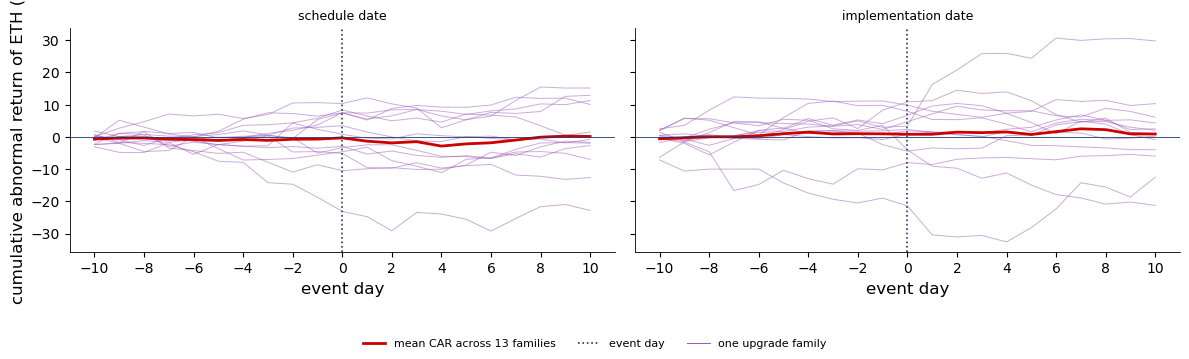

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
days = np.arange(-10, 11)
for k, stage in enumerate(['schedule', 'implementation']):
    Pp = np.array([paths[(n, stage)] for n, _, _ in EV])
    for p_ in Pp:
        ax[k].plot(days, p_, color=ETH, lw=0.7, alpha=0.5)
    ax[k].plot(days, Pp.mean(axis=0), color=RED, lw=2, label=('mean CAR across 13 families' if k == 0 else None))
    ax[k].axvline(0, color=BLUE, ls=':', lw=1.2, label=('event day' if k == 0 else None))
    ax[k].axhline(0, color=BLUE, lw=0.6)
    ax[k].set_title(f'{stage} date', fontsize=9); ax[k].set_xlabel('event day'); ax[k].set_xticks(range(-10, 11, 2))
ax[0].plot([], [], color=ETH, lw=0.7, label='one upgrade family')
ax[0].set_ylabel('cumulative abnormal return of ETH (%)')
slide_fig(fig, 'ba_l7_event', 0.12, ncol=3)

**How to read it.** The individual paths fan out in both directions and the mean path stays near zero: no common revaluation of Ether
around the upgrades. The cross-event tests assume independent events; two schedule dates are only two days apart.